# K-means — segmentacja klientów


**Cel:** Znaleźć segmenty klientów, dobrać k i zinterpretować centroidy w jednostkach biznesowych.



## 1. Środowisko
Jeżeli brakuje bibliotek, odkomentuj poniższą instrukcję instalacji. Instalacja wymaga internetu, sama analiza już nie. Następnie uruchom ponownie kernel.

In [1]:
# %pip install numpy pandas matplotlib scikit-learn
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
SEED = 42
print('Python:', sys.version.split()[0], '| scikit-learn:', sklearn.__version__)

Python: 3.12.14 | scikit-learn: 1.8.0


## Jak działa algorytm?
K-means minimalizuje sumę kwadratów odległości od centroidów: $\sum_i \|x_i-\mu_{c_i}\|^2$. Na przemian przypisuje punkty do najbliższego środka i aktualizuje środki jako średnie.

To uczenie **bez nadzoru**: nie ma etykiety docelowej. Musimy wybrać `k`. Algorytm preferuje zwarte, w przybliżeniu sferyczne klastry; jest wrażliwy na skalę, outliery i inicjalizację.

## 2. Dane: aktywność i wartość zakupów

,wizyty_mies,wydatki_PLN
0,9.291320,441.064058
1,20.974471,616.685401
2,7.936313,616.806725
3,22.021540,605.951164
4,14.676347,1172.097745


,wizyty_mies,wydatki_PLN
count,600.0,600.0
mean,15.1,702.4
std,5.2,291.4
min,4.8,272.1
25%,9.8,472.0
50%,15.0,590.4
75%,20.4,1022.7
max,24.3,1312.4


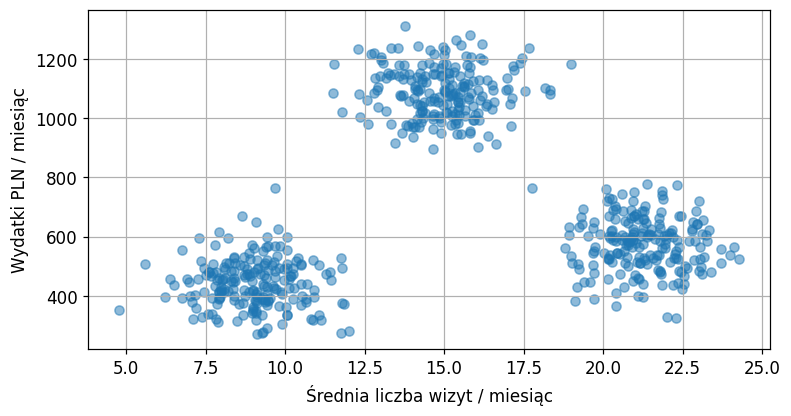

In [2]:
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
A, _ = make_blobs(n_samples=600, centers=[[-3,-2],[0,3],[3,-1]], cluster_std=0.65, random_state=SEED)
X = pd.DataFrame({'wizyty_mies': 15 + 2*A[:,0], 'wydatki_PLN': 700 + 130*A[:,1]})
display(X.head()); display(X.describe().round(1))
plt.scatter(X.wizyty_mies, X.wydatki_PLN, alpha=0.5)
plt.xlabel('Średnia liczba wizyt / miesiąc'); plt.ylabel('Wydatki PLN / miesiąc'); plt.show()

## 3. Dlaczego skalujemy?
Różnica 100 PLN mogłaby zdominować różnicę kilku wizyt. Standaryzacja nadaje obu wymiarom porównywalną skalę. Jest to decyzja o znaczeniu odległości, a nie wyłącznie techniczny obowiązek.

Opisujemy obecną populację, dlatego dopasowujemy skalowanie na całym zbiorze. Przy segmentowaniu przyszłych klientów użyjemy istniejącego skalera i centroidów, bez ponownego `fit`.

In [3]:
scaler = StandardScaler()
Z = scaler.fit_transform(X)

## 4. Wybór liczby klastrów
Inertia maleje wraz ze wzrostem k, więc nie wybieramy minimum bez ograniczeń. Szukamy „łokcia” i porównujemy silhouette (od -1 do 1; wyżej zwykle lepiej). Silhouette nie jest accuracy i może preferować proste geometryczne podziały. Ostateczny wybór musi mieć sens biznesowy.

Kandydat na podstawie silhouette: 3


,k,inertia,silhouette
0,2,548.637486,0.578064
1,3,86.559956,0.781980
2,4,74.234610,0.639497
3,5,62.736829,0.505448
4,6,52.725980,0.354428
5,7,46.955420,0.353679


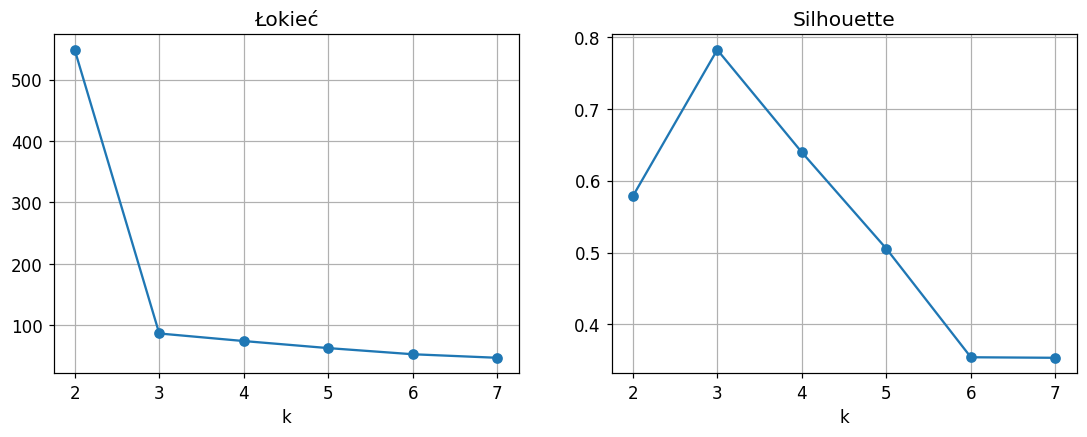

In [4]:
rows = []
for k in range(2, 8):
    m = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    rows.append({'k': k, 'inertia': m.inertia_, 'silhouette': silhouette_score(Z, m.labels_)})
wyniki = pd.DataFrame(rows)
display(wyniki)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(wyniki.k, wyniki.inertia, 'o-'); ax[0].set_title('Łokieć'); ax[0].set_xlabel('k')
ax[1].plot(wyniki.k, wyniki.silhouette, 'o-'); ax[1].set_title('Silhouette'); ax[1].set_xlabel('k')
plt.show()
k = int(wyniki.loc[wyniki.silhouette.idxmax(), 'k'])
print('Kandydat na podstawie silhouette:', k)

## 5. Model, centroidy i profile segmentów

,liczba,wizyty,wydatki
segment,,,
0,200,21.3,575.3
1,200,9.0,443.3
2,200,14.9,1088.7


,wizyty_mies,wydatki_PLN
segment,,
0,21.3,575.3
1,9.0,443.3
2,14.9,1088.7


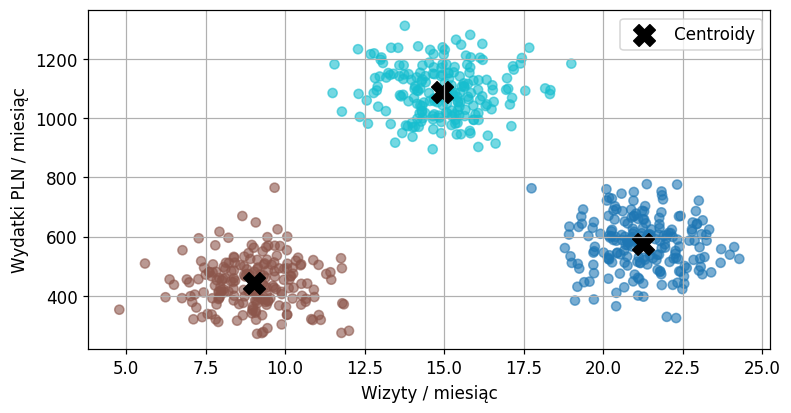

In [5]:
model = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
labels = model.labels_
centra = pd.DataFrame(scaler.inverse_transform(model.cluster_centers_), columns=X.columns)
centra.index.name = 'segment'
segmenty = X.assign(segment=labels)
display(segmenty.groupby('segment').agg(liczba=('wizyty_mies','size'), wizyty=('wizyty_mies','mean'), wydatki=('wydatki_PLN','mean')).round(1))
display(centra.round(1))
plt.scatter(X.wizyty_mies, X.wydatki_PLN, c=labels, cmap='tab10', alpha=0.6)
plt.scatter(centra.wizyty_mies, centra.wydatki_PLN, c='black', marker='X', s=200, label='Centroidy')
plt.xlabel('Wizyty / miesiąc'); plt.ylabel('Wydatki PLN / miesiąc'); plt.legend(); plt.show()

Numery segmentów są umowne: klaster 0 nie oznacza „najlepszy”. Nazwy biznesowe nadajemy po analizie profili. Środek klastra nie musi odpowiadać żadnemu rzeczywistemu klientowi.

## 6. Nowi klienci

In [6]:
nowi = pd.DataFrame({'wizyty_mies': [9, 15, 22], 'wydatki_PLN': [400, 1100, 550]})
nowi['segment'] = model.predict(scaler.transform(nowi[X.columns]))
display(nowi)

,wizyty_mies,wydatki_PLN,segment
0,9,400,1
1,15,1100,2
2,22,550,0


## 7. Eksperyment: skala zmienia wynik
Porównaj podział surowych i skalowanych cech. ARI mierzy zgodność dwóch podziałów niezależnie od numerów klastrów. Nie mierzy prawdy biznesowej.

In [7]:
from sklearn.metrics import adjusted_rand_score
raw = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
print('Zgodność podziałów (ARI):', round(adjusted_rand_score(labels, raw.labels_), 3))

Zgodność podziałów (ARI): 0.677


## 8. Ćwiczenia
1. Ustaw k=2 i k=5. Opisz, które segmenty połączono lub rozbito.
2. Nadaj segmentom nazwy na podstawie średnich, nie numerów.
3. Pomnóż wydatki przez 100. Porównaj rozwiązanie bez skalowania i ze skalowaniem.
4. Dodaj klienta wydającego 100 000 PLN i sprawdź wpływ na centroidy.
5. Wyjaśnij, dlaczego brak etykiet nie oznacza braku założeń.

**Wskazówka:** po standaryzacji dodatnia zmiana jednostki jednej cechy nie powinna istotnie zmienić geometrii. Outlier zmienia zarówno skalowanie, jak i średnie. Rozważ odporne skalowanie i porównanie z metodą gęstościową.

In [8]:
# Miejsce na eksperyment